In [1]:
import sqlite3
import pandas as pd
import numpy as np

db_path = 'chembl_36/chembl_36_sqlite/chembl_36.db' 
conn = sqlite3.connect(db_path)

print("1. 약물-질병 적응증(Indication) 정보 추출 중...")

# mesh_heading(질병명)과 efo_term(오믹스용 병명)을 추가로 가져옵니다.
query_indication = """
    SELECT
        md.chembl_id AS drug_chembl_id,
        di.mesh_id AS mesh_id,
        -- [추가] ID만 있으면 해석이 불가능하므로 이름 필수
        di.max_phase_for_ind AS max_phase
    FROM
        MOLECULE_DICTIONARY md
    JOIN
        DRUG_INDICATION di ON md.molregno = di.molregno
    WHERE
        di.mesh_id IS NOT NULL
        -- (선택) 임상 1상 이상 들어간 의미 있는 데이터만?
        -- AND di.max_phase_for_ind > 0
"""

df_indication = pd.read_sql_query(query_indication, conn)
df_indication = df_indication.replace({np.nan: None})

print(f"추출된 적응증 데이터: {df_indication.shape}")
print(df_indication.head())

# 저장: df_indication.to_csv('drug_indications.csv', index=False)

1. 약물-질병 적응증(Indication) 정보 추출 중...
추출된 적응증 데이터: (59954, 3)
  drug_chembl_id  mesh_id  max_phase
0  CHEMBL1201823  D045743        2.0
1  CHEMBL1201823  D001172        4.0
2  CHEMBL1201584  D009203        3.0
3   CHEMBL271227  D011471        4.0
4   CHEMBL404271  D003920        4.0


In [2]:
df_indication

,drug_chembl_id,mesh_id,max_phase
0,CHEMBL1201823,D045743,2.0
1,CHEMBL1201823,D001172,4.0
2,CHEMBL1201584,D009203,3.0
3,CHEMBL271227,D011471,4.0
4,CHEMBL404271,D003920,4.0
...,...,...,...
59949,CHEMBL6068387,D007251,4.0
59950,CHEMBL6068388,D014611,4.0
59951,CHEMBL6068388,D007251,4.0
59952,CHEMBL6068502,D007154,2.0


In [3]:
df_indication["max_phase"].value_counts()

max_phase
 2.0    22285
 3.0    14760
 1.0    13014
 4.0     8682
 0.5     1089
-1.0      124
Name: count, dtype: int64

In [4]:
data_dir = "chembl-data/compound-disease"

In [5]:
# 4. 중복 제거 (Cleaning)
# 전략: max_phase가 높은 순서로 정렬한 뒤, Drug-Disease가 같으면 첫 번째 것만 남김

df_clean = df_indication.sort_values(by='max_phase', ascending=False).drop_duplicates(
    subset=['drug_chembl_id', 'mesh_id'],
    keep='first'
)

print(f"\n[정리 완료] 중복 제거 후 데이터 크기: {len(df_clean)}")
print(f"제거된 중복 행 수: {len(df_indication) - len(df_clean)}")


[정리 완료] 중복 제거 후 데이터 크기: 55025
제거된 중복 행 수: 4929


In [6]:
df_clean.to_csv(f"{data_dir}/compound-disease_information.csv", index=False)

--- Drug-Disease 상호작용 행렬 생성 및 희소성 분석 ---

1. 행렬 차원 (Dimension): 10072 Drugs x 2178 Diseases
--------------------------------------------------
2. 전체 가능한 조합 수 (Total Elements): 21,936,816
3. 실제 연결된 상호작용 수 (Non-zeros): 55,025
4. 연결되지 않은 조합 수 (Zeros): 21,881,791
--------------------------------------------------
📌 [결과] 데이터 희소성 (Sparsity): 99.7492%
📌 [결과] 데이터 밀도 (Density): 0.2508%


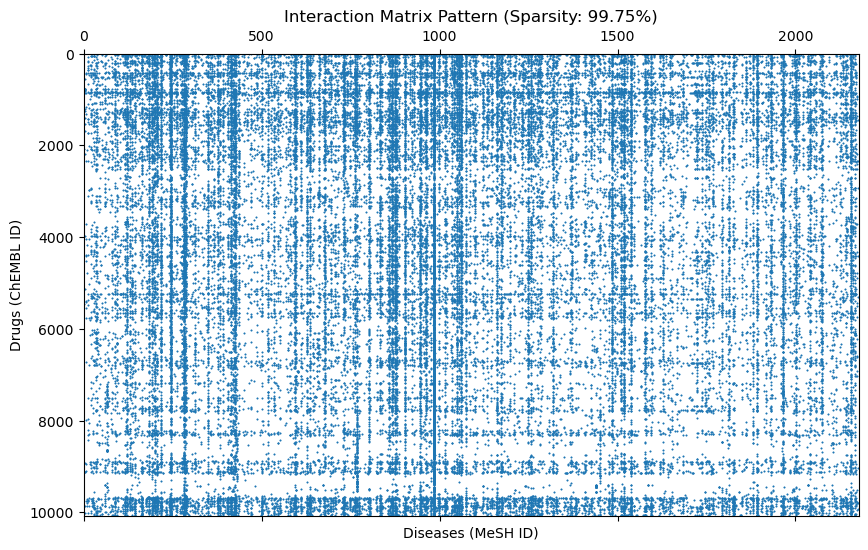

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("--- Drug-Disease 상호작용 행렬 생성 및 희소성 분석 ---\n")

# 1. 교차표(Crosstab)를 이용해 행렬로 변환
# 행(Index): drug_chembl_id, 열(Columns): mesh_id
# 값이 있으면 1, 없으면 0으로 만들기 위해 (matrix > 0).astype(int) 처리
interaction_matrix = pd.crosstab(df_clean['drug_chembl_id'], df_clean['mesh_id'])
interaction_matrix = (interaction_matrix > 0).astype(int)

# 2. 행렬의 크기 확인
n_drugs, n_diseases = interaction_matrix.shape
print(f"1. 행렬 차원 (Dimension): {n_drugs} Drugs x {n_diseases} Diseases")

# 3. 연결 정보(1)와 비연결 정보(0) 개수 계산
total_elements = n_drugs * n_diseases
n_interactions = interaction_matrix.sum().sum() # 1의 개수
n_zeros = total_elements - n_interactions       # 0의 개수

# 4. 희소성(Sparsity) 계산
sparsity = (n_zeros / total_elements) * 100
density = (n_interactions / total_elements) * 100

print("-" * 50)
print(f"2. 전체 가능한 조합 수 (Total Elements): {total_elements:,}")
print(f"3. 실제 연결된 상호작용 수 (Non-zeros): {n_interactions:,}")
print(f"4. 연결되지 않은 조합 수 (Zeros): {n_zeros:,}")
print("-" * 50)
print(f"📌 [결과] 데이터 희소성 (Sparsity): {sparsity:.4f}%")
print(f"📌 [결과] 데이터 밀도 (Density): {density:.4f}%")

# (선택) 5. 행렬 시각화 (Spy Plot)
# 데이터가 너무 크면 heatmap은 깨지므로, 점만 찍어서 패턴을 봅니다.
plt.figure(figsize=(10, 6))
plt.spy(interaction_matrix, markersize=0.5, aspect='auto')
plt.title(f"Interaction Matrix Pattern (Sparsity: {sparsity:.2f}%)")
plt.xlabel("Diseases (MeSH ID)")
plt.ylabel("Drugs (ChEMBL ID)")
plt.show()

In [8]:
print("--- Drug-Disease 중복 데이터 점검 ---\n")

# 1. Drug와 Disease(MeSH ID) 기준으로 그룹핑해서 개수(Count) 세기
dup_check = df_clean.groupby(['drug_chembl_id', 'mesh_id']).size().reset_index(name='count')

# 2. 개수가 1보다 큰(중복된) 경우만 필터링
duplicates = dup_check[dup_check['count'] > 1].sort_values(by='count', ascending=False)

print(f"전체 조합 수: {len(df_clean)}")
print(f"중복된 Drug-Disease 쌍의 개수: {len(duplicates)}")
print("-" * 60)

if len(duplicates) > 0:
    print("[중복 발생 상위 5개 케이스]")
    print(duplicates.head())

    # 3. 실제 데이터 뜯어보기 (가장 많이 중복된 첫 번째 케이스 확인)
    top_dup_drug = duplicates.iloc[0]['drug_chembl_id']
    top_dup_disease = duplicates.iloc[0]['mesh_id']

    print(f"\n[상세 확인] Drug: {top_dup_drug} / Disease: {top_dup_disease}")
    print(df_clean[(df_clean['drug_chembl_id'] == top_dup_drug) &
                   (df_clean['mesh_id'] == top_dup_disease)])
else:
    print("축하합니다! 중복된 데이터가 하나도 없습니다.")

--- Drug-Disease 중복 데이터 점검 ---

전체 조합 수: 55025
중복된 Drug-Disease 쌍의 개수: 0
------------------------------------------------------------
축하합니다! 중복된 데이터가 하나도 없습니다.


In [9]:
print(f"\n[정리 완료] 중복 제거 후 데이터 크기: {len(df_clean)}")
print(f"제거된 중복 행 수: {len(df_indication) - len(df_clean)}")


[정리 완료] 중복 제거 후 데이터 크기: 55025
제거된 중복 행 수: 4929


In [10]:
df_clean

,drug_chembl_id,mesh_id,max_phase
1,CHEMBL1201823,D001172,4.0
59935,CHEMBL6068380,D000086382,4.0
59939,CHEMBL6068382,D000086382,4.0
59940,CHEMBL6068383,D014611,4.0
59941,CHEMBL6068383,D000086382,4.0
...,...,...,...
27786,CHEMBL1593566,D004478,-1.0
27579,CHEMBL373204,D004478,-1.0
26493,CHEMBL3833375,D015817,-1.0
44925,CHEMBL2111135,D006967,-1.0


In [11]:
df_clean

,drug_chembl_id,mesh_id,max_phase
1,CHEMBL1201823,D001172,4.0
59935,CHEMBL6068380,D000086382,4.0
59939,CHEMBL6068382,D000086382,4.0
59940,CHEMBL6068383,D014611,4.0
59941,CHEMBL6068383,D000086382,4.0
...,...,...,...
27786,CHEMBL1593566,D004478,-1.0
27579,CHEMBL373204,D004478,-1.0
26493,CHEMBL3833375,D015817,-1.0
44925,CHEMBL2111135,D006967,-1.0


In [12]:
# 최종 데이터를 CSV 파일로 저장
df_clean.to_csv(f"{data_dir}/compound-disease_information.csv", index=False)
print(f"저장 완료: {data_dir}/compound-disease_information.csv")

저장 완료: chembl-data/compound-disease/compound-disease_information.csv
